In [1]:
%pylab inline
import os
import pandas as pd
import numpy as np
import astropy.io.fits as pyfits
import astropy.table as astTable
import sim_analysis_utilities as utilities
import smatch
aname='/work/xiangchong.li/work/COSMOS/cosmos_leauthaud_2007/COSMOS_ACS_catalog/acs_clean_only.fits'
dbDir='./wrkDir/database/s19-COSMOS/'
if True:
    outDir      =   './wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/plot/others/'

Populating the interactive namespace from numpy and matplotlib


# 3 catalogs

* HSC wdie_depth_best catalog (S16A sim)
* HSC wdie_depth_median catalog (S16A sim)
* HSC wdie_depth_worst catalog (S16A sim)

In [2]:
coscat=pyfits.getdata(aname)
coscat=coscat[coscat['mu_class']<3]
bcat=pyfits.getdata(os.path.join(dbDir,'COSMOS_WIDE_DEPTH_BEST.fits'))
mcat=pyfits.getdata(os.path.join(dbDir,'COSMOS_WIDE_DEPTH_MEDIAN.fits'))
wcat=pyfits.getdata(os.path.join(dbDir,'COSMOS_WIDE_DEPTH_WORST.fits'))

In [96]:
def main(cat0,cat):
    ra=cat0['ALPHAPEAK_J2000']
    dec=cat0['DELTAPEAK_J2000']
    bmask=utilities.get_wl_flags(cat)
    cat=cat[bmask]
    bmatch   =   smatch.match(cat['i_ra'],cat['i_dec'],0.6/3600.,ra,dec,maxmatch=1)      # For a galaxy in sim find the closest one in HSC Wide field
    cmsk=np.zeros(len(ra),dtype=bool)
    cmsk[bmatch['i2']]=True
    cat1=cat0[cmsk]
    cat=cat[bmatch['i1']]
    fmsk=(cat1['mu_class']==2) & (cat['i_extendedness_value']==1)
    mag=utilities.get_imag(cat)
    nb=9
    if True:
        bd=np.percentile(mag,np.linspace(0,100,nb))
    else:
        bd=np.linspace(np.min(mag),np.max(mag)+0.01,nb)
    out=np.zeros(nb-1)
    std=np.zeros(nb-1)
    for i in range(nb-1):
        msk=(mag>bd[i])&(mag<bd[i+1])
        fmski=fmsk[msk]
        out[i]=np.sum(fmski)/np.sum(msk)
        std[i]=np.sqrt(np.sum(fmski))/np.sum(msk)
    print(np.sum(fmsk)/len(cat1))
    magave=(bd[1:]+bd[:-1])/2.
    print(magave,out)
    return np.sum(fmsk)/len(cat1),magave,out,std

In [102]:
bb,ba,bo,be=main(coscat,bcat)
mm,ma,mo,me=main(coscat,mcat)
ww,wa,wo,we=main(coscat,wcat)

/work/xiangchong.li/superonionGW/code/FPFS_Private/FPFSBASE/python/sim_analysis_utilities.py:1777: RuntimeWarning: invalid value encountered in less
  (get_imag_A10(catalog)<25.5)& \
/work/xiangchong.li/superonionGW/code/FPFS_Private/FPFSBASE/python/sim_analysis_utilities.py:1777: RuntimeWarning: invalid value encountered in less_equal
  (get_imag_A10(catalog)<25.5)& \
/work/xiangchong.li/superonionGW/code/FPFS_Private/FPFSBASE/python/sim_analysis_utilities.py:1777: RuntimeWarning: invalid value encountered in greater_equal
  (get_imag_A10(catalog)<25.5)& \


0.0022223481342978197
[18.84867764 22.29796982 22.97606182 23.4145422  23.74343109 24.00802135
 24.23123646 24.43606186] [0.00266949 0.00120882 0.00171259 0.00226655 0.00206508 0.00246802
 0.00282059 0.00256888]
0.002588689013920807
[18.80174875 22.263376   22.94418049 23.38667846 23.71972859 23.98823321
 24.21688819 24.43141055] [0.00221893 0.00126796 0.00211316 0.00227177 0.00301141 0.00343425
 0.00327574 0.00311708]
0.0036997371239411935
[18.51582217 22.18314362 22.87185752 23.32078326 23.65777326 23.9319365
 24.17069054 24.41035366] [0.00367197 0.00205853 0.00300434 0.00367217 0.00333853 0.00406142
 0.00500723 0.00478469]


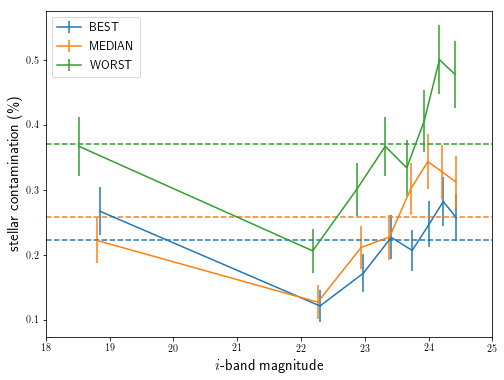

In [103]:
cm=plt.get_cmap('tab10')
xmin=18;xmax=25
ccp=np.linspace(xmin,xmax,30)
fig=plt.figure(figsize=(8,6))
plt.errorbar(ba,bo*100,be*100.,c=cm(0),label='BEST')
plt.plot(ccp,bb*np.ones(len(ccp))*100,'--',c=cm(0))
plt.errorbar(ma,mo*100,me*100.,c=cm(1),label='MEDIAN')
plt.plot(ccp,mm*np.ones(len(ccp))*100,'--',c=cm(1))
plt.errorbar(wa,wo*100,we*100.,c=cm(2),label='WORST')
plt.plot(ccp,ww*np.ones(len(ccp))*100,'--',c=cm(2))

plt.xlabel(r'$i$-band magnitude',fontsize=15)
plt.ylabel('stellar contamination (\%)',fontsize=15)
plt.xlim(xmin,xmax)

plt.legend(loc='upper left',fontsize=12)
fig.savefig(os.path.join(outDir,'stellar_contam.eps'))
fig.savefig(os.path.join(outDir,'stellar_contam.png'))

Text(0, 0.5, 'dec')

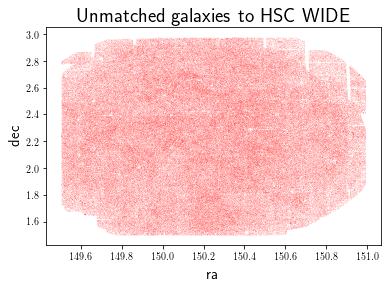

In [12]:
plt.scatter(bcat['i_ra'],bcat['i_dec'],s=0.0001,c='red')
plt.title('Unmatched galaxies to HSC WIDE',fontsize=20)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)